# Image Operations Lab

All of the programming assignments are to be done in Python using additional libraries specified in the assignments. There are many libraries available, some of which we will be using, and you are welcome to use them with one exception: if the library or a function within it performs the specific function you are asked to code, you may not use that other than perhaps as a reference to compare against. All of the code you submit must be your own. You are welcome to turn in a completed jupyter notebook.


## Pre-lab Notes

We will be using the same racoon image from last lab. Plot it to make sure it loads correctly.


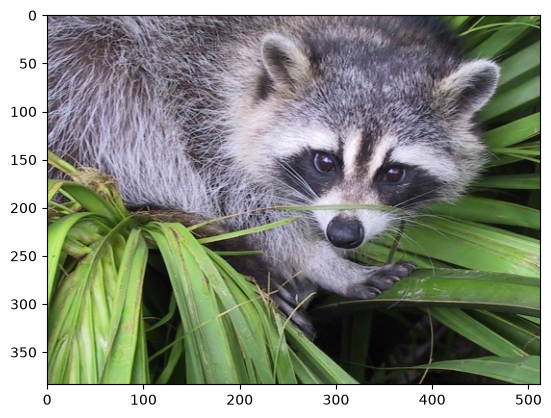

In [29]:
import matplotlib.pyplot as plt
import numpy as np

racoon = plt.imread('racoon.jpg')
plt.imshow(racoon); plt.show()

We will also be working on grayscale images for this lab. While all the kernel operations we learned work on color images as well, there are a few nuances we don't want to worry about for this lab. We will import a grayscale function.


In [30]:
def toGrayScale(image):
    result = 0.299*image[:,:,0] + 0.587*image[:,:,1] + 0.114*image[:,:,2]
    return result

Now you are ready to start the lab. Implement each of the following functions. Use the provided test cases to test your functions. **Remember, your code should be implemented entirely in NumPy with no external packages like SciPy or OpenCV.**


## Function 1: Uniform Blurring (10 pts)

Takes in a grayscale image and returns a corresponding result that has been blurred (spatially filtered) using a uniform averaging. Allow the user to specify the size of the kernel (ex. size=3 would give a 3x3 kernel). You can ignore the edge pixels. (Hint: np.sum() may be useful)


In [31]:
#size = 3 means we are thinking about a 3 × 3 area around each pixel.
def blur(image,size=3):
    # Create a result buffer so that you don't affect the original image
    result = np.zeros(image.shape)
    
    # Your code here
    rows, cols = image.shape
    radius = size // 2

    for i in range(radius, rows - radius):
        for j in range(radius, cols - radius):
            #This selects a 3 × 3 neighborhood around the current pixel. Start one row before i and go up to, but not including, i+2.
            result[i, j] = np.mean(image[i-radius:i+radius+1, j-radius:j+radius+1])
    
    return result



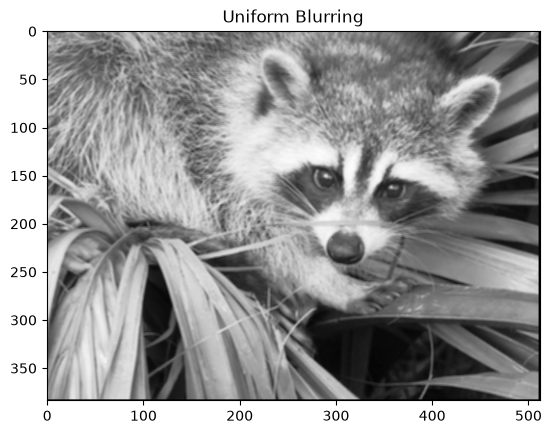

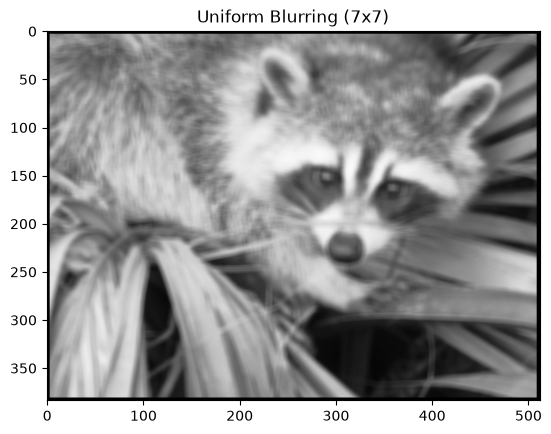

In [32]:
# Test Cases
gray_racoon = toGrayScale(racoon)
blur_racoon = blur(gray_racoon)
plt.imshow(blur_racoon,cmap="Greys_r",vmin=0,vmax=255); plt.title("Uniform Blurring")
plt.show()

blur_racoon2 = blur(gray_racoon, 7)
plt.imshow(blur_racoon2,cmap="Greys_r",vmin=0,vmax=255); plt.title("Uniform Blurring (7x7)")
plt.show()

## Function 2: Median Filter (10 pts)

Takes in a grayscale image and returns a corresponding result that has been median filtered. Allow the user to specify the size of the kernel (ex. size=3 would give a 3x3 kernel). You can ignore the edge pixels.


In [33]:

def medianFilter(image,size=3):
    # Create a result buffer so that you don't affect the original image
    result = np.zeros(image.shape)
    
    # Your code here
    rows, cols = image.shape
    radius = size // 2

    for i in range(radius, rows - radius):
        for j in range(radius, cols - radius):
            # This selects a 3 × 3 neighborhood around the current pixel. Start one row before i and go up to, but not including, i+2.
            result[i, j] = np.median(image[i-radius:i+radius+1, j-radius:j+radius+1])

    return result

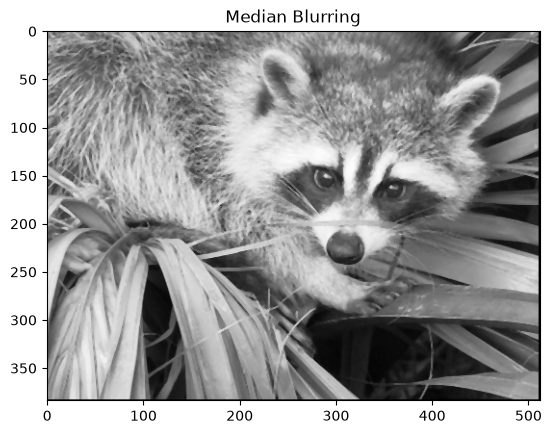

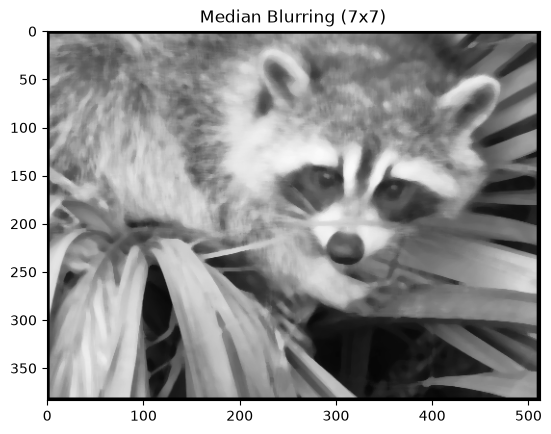

In [34]:
# Test Cases
gray_racoon = toGrayScale(racoon)
median_racoon = medianFilter(gray_racoon)
plt.imshow(median_racoon,cmap="Greys_r",vmin=0,vmax=255); plt.title("Median Blurring")
plt.show()

median_racoon2 = medianFilter(gray_racoon, 7)
plt.imshow(median_racoon2,cmap="Greys_r",vmin=0,vmax=255); plt.title("Median Blurring (7x7)")
plt.show()

## Function 3: General Convolution (10 pts)

Now that you have written a couple of different kernels, write a general convolution function that takes in an image and kernel (stored as a numpy array), and performs the appropriate convolution. You can assume the kernel is 3x3 if you would like, but it is not much harder to do a general size kernel as well.

**Note**: For generality, do not perform normalization, clipping, or type conversion within the function. This will save you heartache when you implement Edge Detection later.


In [35]:
def convolution(image,kernel):
    # Create a result buffer so that you don't affect the original image
    result = np.zeros(image.shape)
    
    # Your code here
    rows, cols = image.shape

    radius = kernel.shape[0] // 2  # Assuming kernel is square and has odd dimensions
    for i in range(radius, rows - radius):
        for j in range(radius, cols - radius):
            #This selects a 3 × 3 neighborhood around the current pixel. Start one row before i and go up to, but not including, i+2.
            result[i, j] = np.sum(image[i-radius:i+radius+1, j-radius:j+radius+1] * kernel)
    
    return result


To make sure your general convolution is working, compare the following test case with your original blur results.


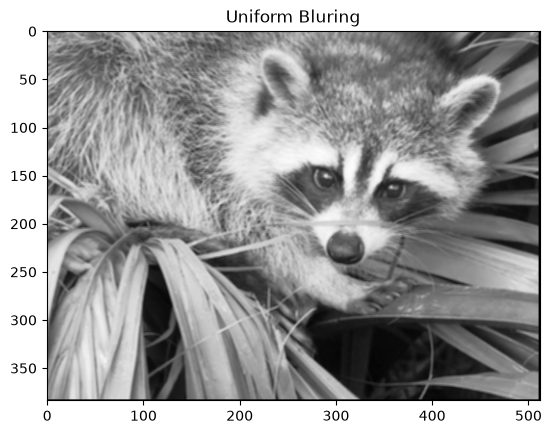

In [36]:
# Test Cases
gray_racoon = toGrayScale(racoon)

blur_kernel = np.array([[1, 1, 1],
                        [1, 1, 1],
                        [1, 1, 1]])

blur_racoon2 = convolution(gray_racoon, blur_kernel)/9.0
blur_racoon2 = np.clip(blur_racoon2,0,255).astype(np.uint8)
plt.imshow(blur_racoon2,cmap="Greys_r",vmin=0,vmax=255); plt.title("Uniform Bluring")
plt.show()

## Function 4: Sharpening (10 pts)

Takes in a grayscale image and returns a corresponding result that has been sharpened using an unsharp masking kernel that has a 6 in the middle and -1s for the four-connected neighbors. You can use your general convolution function. You can ignore the edge pixels. **Don't forget to normalize your results.**


In [37]:
def sharpen(image):
    kernel = np.array([[ 0, -1,  0],
                       [-1,  6, -1],
                       [ 0, -1,  0]])

    result = convolution(image, kernel)
    result = result / np.sum(kernel)          # normalizing
    result = np.clip(result, 0, 255).astype(np.uint8)
    return result



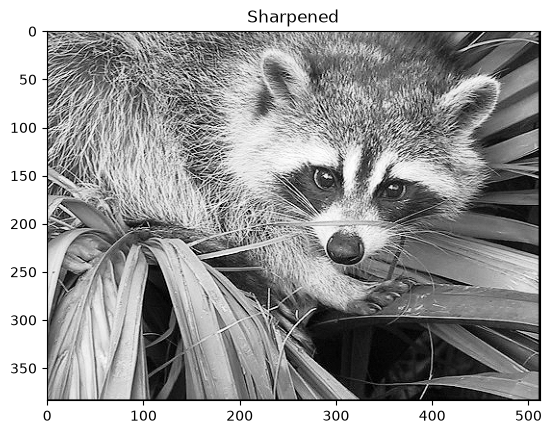

In [38]:
# Test Cases
gray_racoon = toGrayScale(racoon)
sharpen_racoon = sharpen(gray_racoon)
plt.imshow(sharpen_racoon,cmap="Greys_r",vmin=0,vmax=255); plt.title("Sharpened")
plt.show()

## Function 5: Edge Detection (10 pts)

Takes in a grayscale image and returns a corresponding result that shows the gradient magnitude of the input. Use a Sobel kernel. You may afterward scale the result for visibilty if you wish when you demonstrate the function. You can use your general convolution function. You can ignore the edge pixels.


In [39]:
def edgeDetect(image):
    sobel_x = np.array([[-1, 0, 1],
                         [-2, 0, 2],
                         [-1, 0, 1]])

    sobel_y = np.array([[-1, -2, -1],
                         [ 0,  0,  0],
                         [ 1,  2,  1]])

    gx = convolution(image, sobel_x)
    gy = convolution(image, sobel_y)

    magnitude = np.sqrt(gx**2 + gy**2)
    magnitude = np.clip(magnitude, 0, 255).astype(np.uint8)
    return magnitude



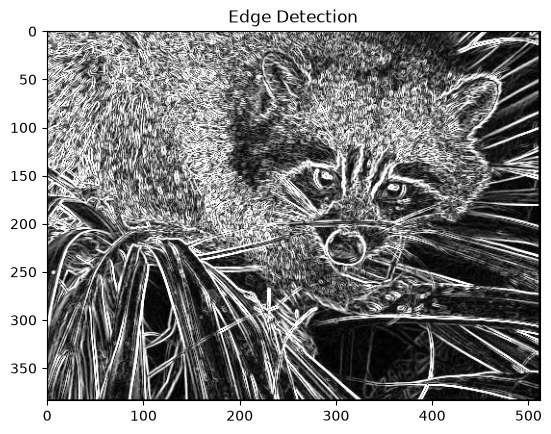

In [40]:
# Test Cases
gray_racoon = toGrayScale(racoon)
edge_racoon = edgeDetect(gray_racoon)
plt.imshow(edge_racoon,cmap="Greys_r",vmin=0,vmax=255); plt.title("Edge Detection")
plt.show()